In [1]:
import datetime
import warnings
from rocketpy import Environment, Flight, Rocket, GenericMotor, Parachute, Function
from rocketpy.simulation import FlightDataExporter
from rocketpy.plots.compare import CompareFlights # allows for comparing data between different rocketpy flight objects and visualizing them
from rocketpy.simulation import FlightComparator, FlightDataImporter # allows for comparing data between a rocketpy flight and external data
from rocketpy.utilities import fin_flutter_analysis # only works with trapezoidal fins i think and i'm not sure how accurate it is yet

In [2]:
DISPLAY_EXTRA_INFO: bool = True # If each component of the Flight and Rocket should display information on it, like Environment and Motor data
SENSOR_REFRESH_RATE: int = 100 # Hz - Rate at which the trigger function is ran to deploy a parachute (simulating onboard sensors)
COMPARISON_SIM_PATH: str | None = "openrocketsim.csv" # The path to the csv sim file of a reference simulation to compare this simulation to (None for no comparison). Keep exported data in SI units
EXPORT_FLIGHT_PATH: str | None = "flight.kml" # The path to where the KML file of the flight path should be stored (None for don't export). This file can be imported into Google Earth to view the flight path
PLAYBACK_SPEED: float = 1.0 # The speed at which the visual flight simulation should start at (can be changed while viewing)
TIME_STEP: float = 0.02 # Seconds per frame in the visual flight simulation
STOP_AT_APOGEE: bool = True # If the flight should stop being simulated when reaching apogee
CAMERA_MODE: str = "static" # "static", "follow", "ground", or "body" - Manages how the camera moves in the visual flight simulation
COLOR_BY: str = "speed" # "speed", "mach", "dynamic_pressure", "acceleration", "altitude", or None - Colors the path of the rocket depending on this value (in the visual flight simulation)


Gravity Details

Acceleration of gravity at surface level:    9.7775 m/s²
Acceleration of gravity at  80.000 km (ASL): 9.5379 m/s²


Launch Site Details

Launch Date: 2026-11-05 12:00:00 UTC
Launch Site Latitude: 0.00000°
Launch Site Longitude: 0.00000°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 166021.44 W|E    0.00 N
Launch Site UTM zone: 31N
Launch Site Surface Elevation: 910.0 m


Atmospheric Model Details

Atmospheric Model Type: custom_atmosphere
custom_atmosphere Maximum Height: 80.000 km

Surface Atmospheric Conditions

Surface Wind Speed: 4.50 m/s
Surface Wind Direction: 270.00°
Surface Wind Heading: 90.00°
Surface Pressure: 908.56 hPa
Surface Temperature: 282.25 K
Surface Air Density: 1.121 kg/m³
Surface Speed of Sound: 336.56 m/s


Earth Model Details

Earth Radius at Launch site: 6378.14 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034



Gravity Model Plots


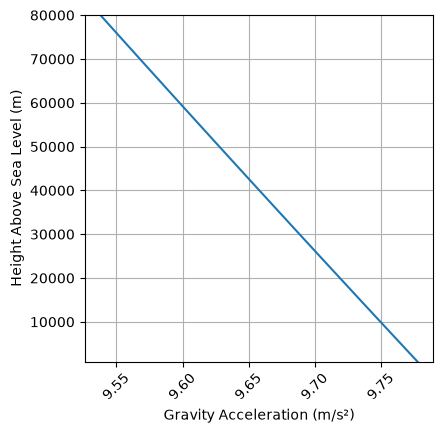



Atmospheric Model Plots


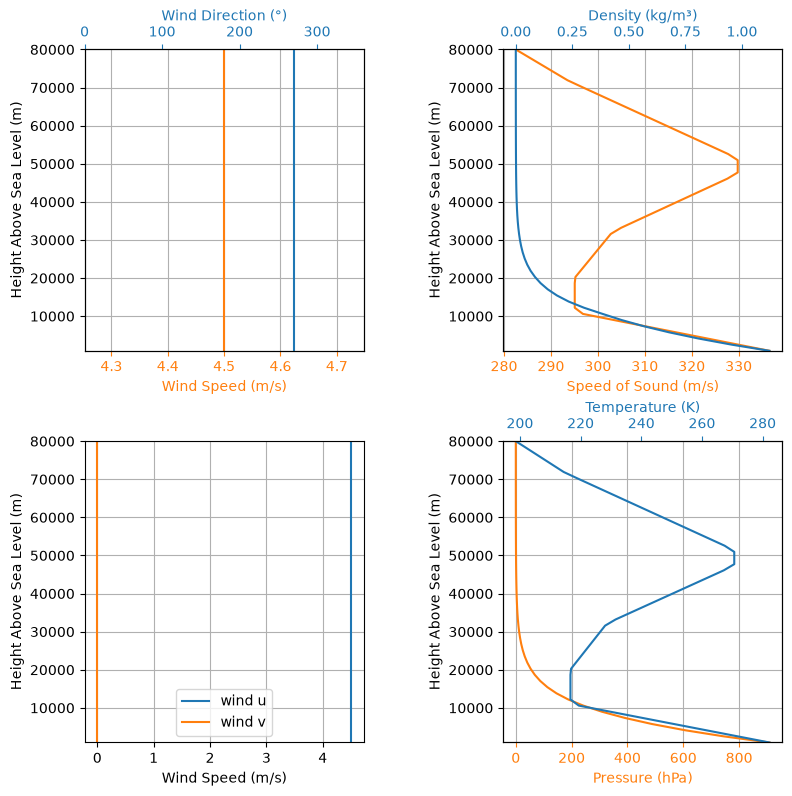

In [3]:
env = Environment(elevation=910) # Set location (latitude, longitude)
date = datetime.date(2026, 11, 5)
env.set_date((date.year, date.month, date.day, 12))
env.set_atmospheric_model(
    type="custom_atmosphere",
    wind_u = 4.5,
)
if DISPLAY_EXTRA_INFO:
    env.all_info()
del date

In [4]:
# cgs here are relative to their components like in MAPLEAF
current_position = 0
component_data = {}
component_data["nose_cone"] = {
    "mass": 0.641, # CAD
    "base_diameter": 0.09144,
    "position": current_position, # relative to top of nose cone
    "length": 0.366, # from OpenRocket 10/17
    "cg": -0.286, # from OpenRocket 10/17
    "moi": (0.0155804408333333, 0.0155804408333333, 0.000559215),
}
component_data["nose_cone_tip"] = {
    "mass": 0.059, # CAD
    "position": current_position, # relative to top of nose cone
    "cg": -0.0318, # from OpenRocket 10/17
}
component_data["nose_cone_insert"] = {
    "mass": 0.2, # from OpenRocket 10/17
    "position": current_position - 0.0635, # relative to top of nose cone
    "cg": -0.0318, # from OpenRocket 10/17
}
current_position -= component_data["nose_cone"]["length"]

component_data["recovery_tube"] = {
    "mass": 0.304, # CAD
    "position": current_position, # position of bottom of nose cone
    "length": 0.305,
    "cg": -0.152, # from OpenRocket 10/17
    "moi": (0.002989, 0.002989, 0.001271),
}
component_data["coupler+avionics"] = {
    "mass": 1.098, # from OpenRocket 10/17
    "position": current_position - 0.206, # relative to top of recovery tube
    "cg": -0.102, # from OpenRocket 10/17
    "moi": (0.006084, 0.006084, 0.004599),
}
component_data["camera_assembly"] = {
    "mass": 0.345,
    "position": current_position - 0.425, # relative to top of recovery tube
    "cg": -0.0267, # from OpenRocket 10/17
    "moi": (0.000803, 0.000803, 0.001442),
}
current_position -= component_data["recovery_tube"]["length"]

component_data["fin_can"] = {
    "mass": 0.685, # julian (comment from MAPLEAf)
    "position": current_position,
    "length": 0.711,
    "cg": -0.356, # from OpenRocket
    "moi": (0.034577, 0.034577, 0.002864),
}
component_data["fins"] = {
    "mass": 0.678, # 0.558 on MAPLEAF, 0.678 on OpenRocket 10/17
    "position": current_position - (component_data["fin_can"]["length"] - 0.279 - 0), # effectively a position relative to back of fin can - first number is fin root chord and second is distance from end of fin can
    "cg": -0.153, # from OpenRocket 10/17
    "num_fins": 3,
    "root_chord": 0.2794,
    "tip_chord": 0.0889,
    "span": 0.09652,
    "type": "free_form",
    "shape_points": [
        (0, 0),
        (0.127, 0.0965),
        (0.216, 0.0965),
        (0.279, 0)
    ],
}
current_position -= component_data["fin_can"]["length"]

component_data["boat_tail"] = {
    "mass": 0.24, # CAD
    "position": current_position,
    "length": 0.06,
    "cg": -0.0279, # from OpenRocket 10/17
    "start_diameter": 0.0914,
    "end_diameter": 0.06,
    "moi": (0.01, 0.01, 0.0001),
}
current_position -= component_data["boat_tail"]["length"]

component_data["recovery_system"] = {
    # Mass and cg for this 'component' are derived from the mass and cg of each stage. This is not an actual component, but just combines all stages into one component
    "position": 0,
    "stages": [
        {
            "name": "drogue",
            "trigger": "apogee",
            "chute_area": 0.2922466566,
            "cd": 0.970, # Drag coefficient
            "delay": 0.1,
            "mass": 0.0765,
            "position": component_data["nose_cone"]["position"] - 0.028,
            "cg": -0.0185, # from OpenRocket 10/17
        },
        {
            "name": "main",
            "trigger": 457, # altitude
            "chute_area": 0.533,
            "cd": 0.8, # Drag coefficient
            "delay": 0.1,
            "mass": 0.3,
            "position": component_data["recovery_tube"]["position"] - 0.1,
            "cg": -0.035,
        },
    ],
}
del current_position

total_mass = 0
total_cg = 0
for stage in component_data["recovery_system"]["stages"]:
    mass = stage["mass"]
    total_mass += mass
    total_cg += mass * (stage["position"] + stage["cg"])
total_cg /= total_mass
component_data["recovery_system"]["mass"] = total_mass
component_data["recovery_system"]["cg"] = total_cg
del total_mass, total_cg

launch_data = {
    "heading": 270,
    "rotation_angle": 2,
    "rail_length": 4.3688,
}

def get_mass_without_motor() -> float:
    mass = 0
    for component, data in component_data.items():
        result = data.get("mass")
        if result is not None:
            mass += data["mass"]
        else:
            warnings.warn(f"{component} does not have a mass!")
    return mass

def get_center_of_mass_without_motor() -> float:
    total_mass = 0
    components = 0
    for component, data in component_data.items():
        position = data.get("position")
        cg = data.get("cg")
        mass = data.get("mass")
        if position is not None and cg is not None and mass is not None:
            components += mass * (position + cg) # mass * global cg
            total_mass += mass
        else:
            missing = [name for name, val in {"position": position, "cg": cg, "mass": mass}.items() if val is None]
            warnings.warn(f"{component} does not have a {" or ".join(missing)}!")
    return components / total_mass

def get_moment_of_inertia() -> tuple[float, float, float]:
    com = get_center_of_mass_without_motor()
    total_x = 0
    total_y = 0
    total_z = 0
    for component, data in component_data.items():
        moment = data.get("moi")
        mass = data["mass"]
        position = data["position"]
        if moment is None:
            print(f"{component} has no listed moi, treating it like a point mass (mass {mass}kg)")
            xMoment = mass * (abs(position - com) ** 2)
            moment = (xMoment, xMoment, 0)
        shifted_moment = (moment[0] + mass * (abs(position - com) ** 2), moment[1] + mass * (abs(position - com) ** 2), moment[2]) # Parallel axis theorem for x and y but z stays same
        total_x += shifted_moment[0]
        total_y += shifted_moment[1]
        total_z += shifted_moment[2]
    return (total_x, total_y, total_z)

In [5]:
stormfly = Rocket(
    radius=component_data["nose_cone"]["base_diameter"] / 2,
    mass=get_mass_without_motor(),
    inertia=get_moment_of_inertia(),
    power_off_drag=0.5,
    power_on_drag=0.5,
    center_of_mass_without_motor=get_center_of_mass_without_motor(),
    coordinate_system_orientation="tail_to_nose",
)

nose_cone_tip has no listed moi, treating it like a point mass (mass 0.059kg)
nose_cone_insert has no listed moi, treating it like a point mass (mass 0.2kg)
fins has no listed moi, treating it like a point mass (mass 0.678kg)
recovery_system has no listed moi, treating it like a point mass (mass 0.3765kg)


Motor Details
Total Burning Time: 3.69 s
Total Propellant Mass: 1.177 kg
Structural Mass Ratio: 0.396
Average Propellant Exhaust Velocity: 2070.841 m/s
Average Thrust: 660.537 N
Maximum Thrust: 1078.9 N at 0.07 s after ignition.
Total Impulse: 2437.380 Ns



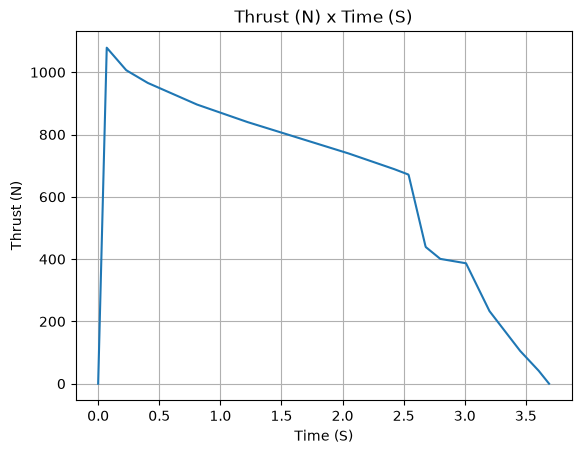

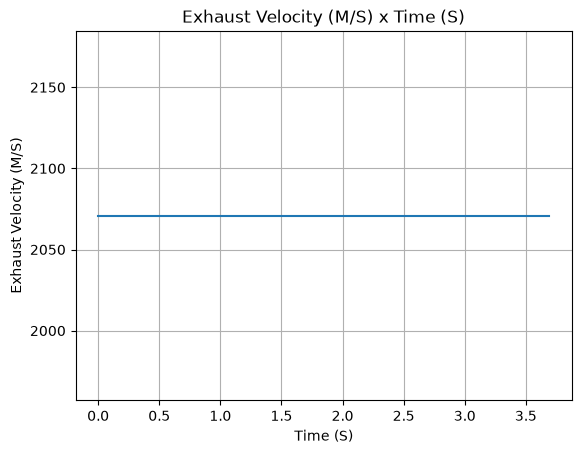

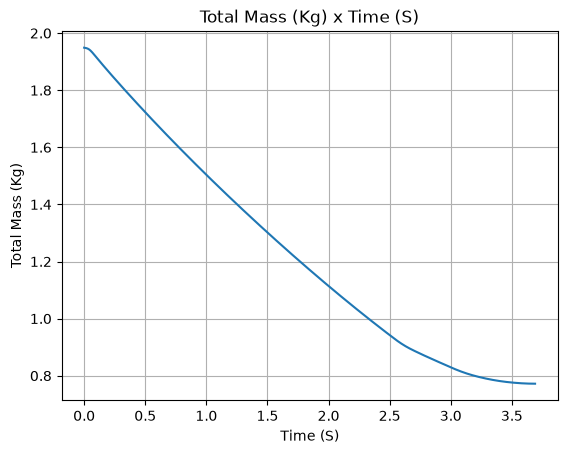

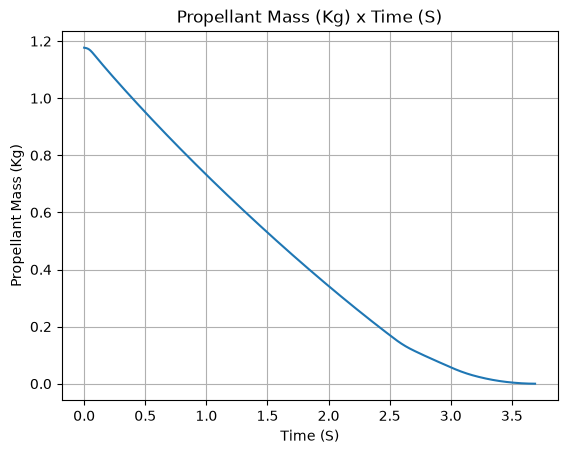

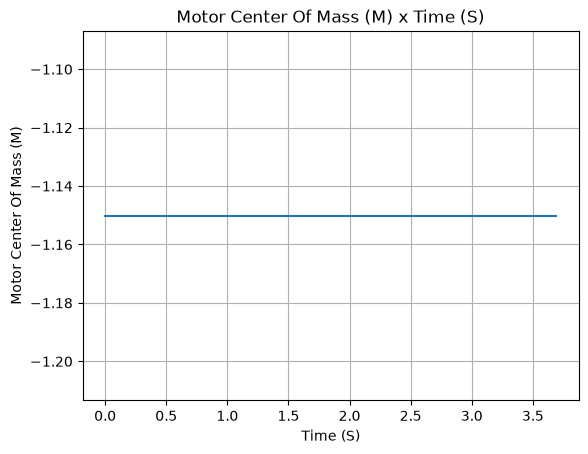

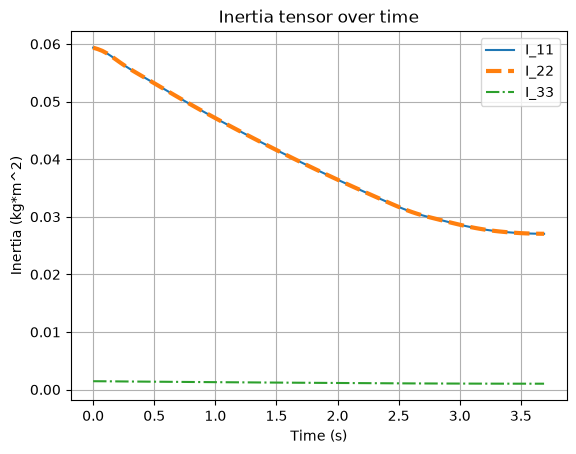

In [6]:
motor = GenericMotor(
    thrust_source=r"thrust.csv",
    burn_time=3.69,
    chamber_radius=0.027,
    chamber_height=0.572,
    chamber_position=component_data["fin_can"]["position"] - 0.47915, # 10 cm father from nose cone than middle
    propellant_initial_mass=1.177,
    nozzle_radius=0.0156,
    dry_mass=0.772,
    center_of_dry_mass_position=component_data["fin_can"]["position"] - 0.47915, # 10 cm farther from nose cone than middle
    dry_inertia=(0.027047, 0.027047, 0.001019),
    nozzle_position=component_data["fin_can"]["position"] - component_data["fin_can"]["length"] - 0.0473,
    interpolation_method="linear",
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)
stormfly.add_motor(motor, position=0)
if DISPLAY_EXTRA_INFO:
    motor.all_info()

Identification of the AeroSurface:
----------------------------------
Name: Nose Cone
Python Class: <class 'rocketpy.rocket.aero_surface.nose_cone.NoseCone'>

Geometric information of NoseCone:
----------------------------------
Length: 0.366 m
Kind: lvhaack
Base radius: 0.046 m
Reference rocket radius: 0.046 m
Reference radius ratio: 1.000

Lift information of the AeroSurface:
-----------------------------------
Center of Pressure position in local coordinates: (0.000, 0.000, 0.206)
Lift coefficient derivative at Mach 0 and AoA 0: 2.000 1/rad



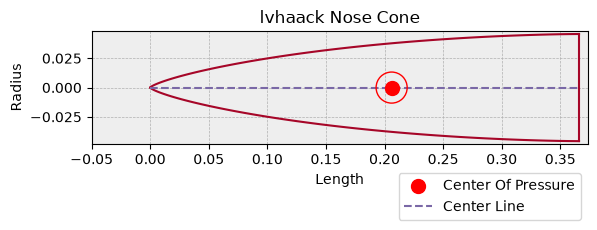

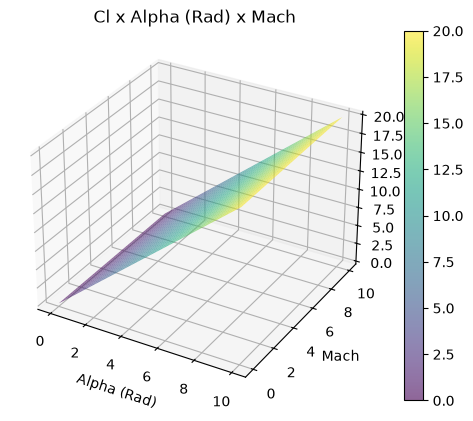

In [7]:
nose_cone = stormfly.add_nose(length=component_data["nose_cone"]["length"], kind="lvhaack", position=component_data["nose_cone"]["position"])
if DISPLAY_EXTRA_INFO:
    nose_cone.all_info()

Identification of the AeroSurface:
----------------------------------
Name: Fins
Python Class: <class 'rocketpy.rocket.aero_surface.fins.free_form_fins.FreeFormFins'>

Geometric information of the fin set:
-------------------------------------
Number of fins: 3
Reference rocket radius: 0.046 m
Root chord: 0.279 m
Span: 0.097 m
Cant angle: 0.000 ° or 0.000 rad
Longitudinal section area: 0.018 m²
Aspect ratio: 1.049 
Gamma_c: 0.320 m
Mean aerodynamic chord: 0.040 m

Roll information of the fin set:
--------------------------------
Geometric constant: 0.000 m
Damping interference factor: 1.210 rad
Forcing interference factor: 0.935 rad

Lift information of the fin set:
--------------------------------
Lift interference factor: 1.321 m
Center of Pressure position in local coordinates: (0.000, 0.000, 0.102)
Lift Coefficient derivative (single fin) at Mach 0 and AoA 0: 4.159


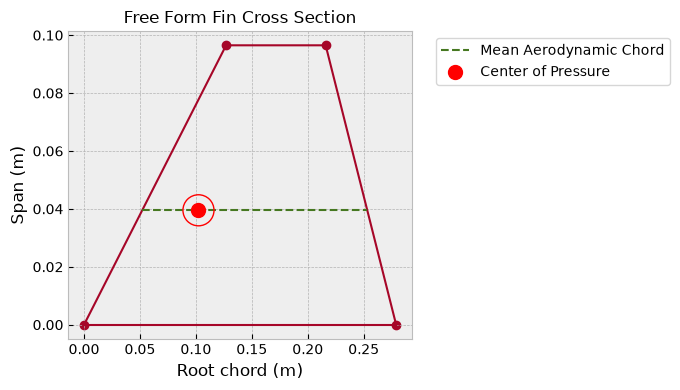

Roll parameters:


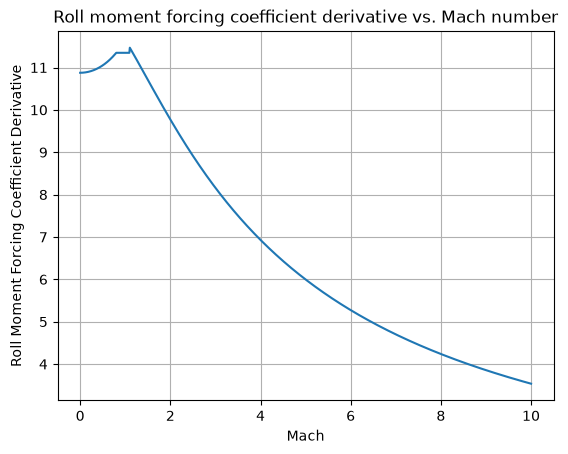

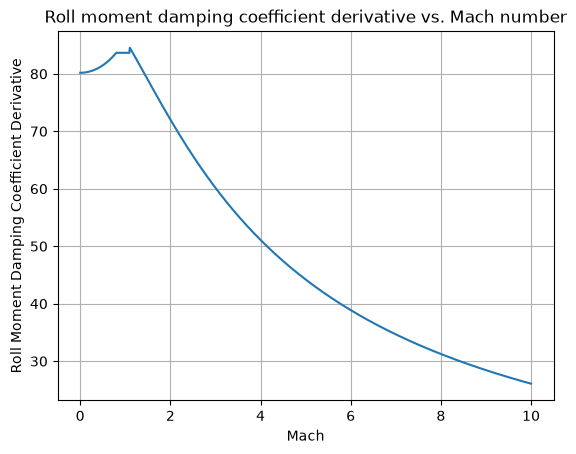

Lift coefficient:


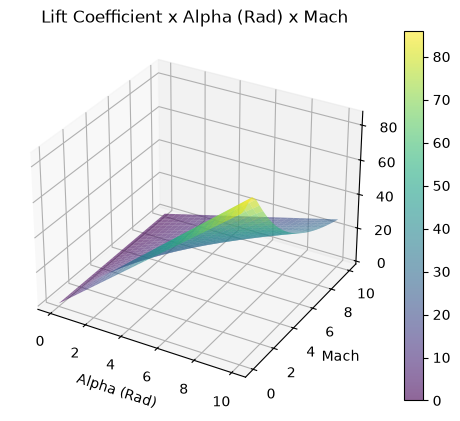

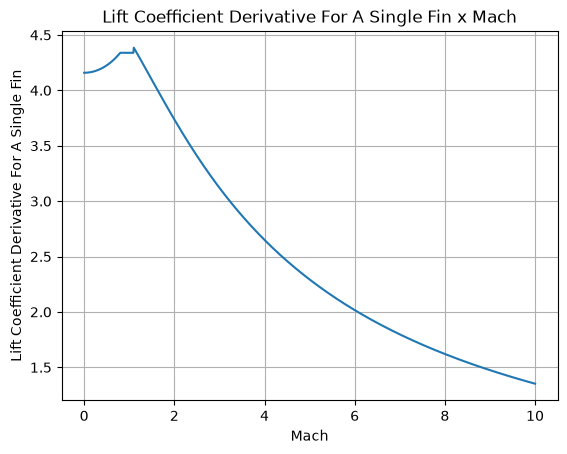

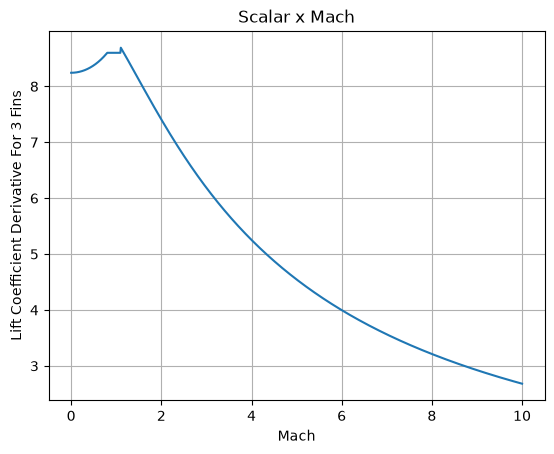

In [8]:
fin_data = component_data["fins"]
type = fin_data["type"]
fin_set = None
if type == "free_form":
    fin_set = stormfly.add_free_form_fins(
        n=fin_data["num_fins"],
        position=fin_data["position"],
        shape_points=fin_data["shape_points"],
        cant_angle=0,
        airfoil=None,
    )
elif type == "trapezoidal":
    fin_set = stormfly.add_trapezoidal_fins(
        n=fin_data["num_fins"],
        root_chord=fin_data["root_chord"],
        tip_chord=fin_data["tip_chord"],
        span=fin_data["span"],
        position=fin_data["position"],
        cant_angle=0,
        airfoil=None,
    )
if fin_set is None:
    raise RuntimeError(f"Fin type {type} is undefined")

if DISPLAY_EXTRA_INFO:
    fin_set.all_info()
del fin_data, type

Identification of the AeroSurface:
----------------------------------
Name: Tail
Python Class: <class 'rocketpy.rocket.aero_surface.tail.Tail'>

Geometric information of the Tail:
----------------------------------
Top radius: 0.046 m
Bottom radius: 0.030 m
Reference radius: 0.091 m
Length: 0.060 m
Slant length: 0.062 m
Surface area: 0.014750 m²

Lift information of the AeroSurface:
-----------------------------------
Center of Pressure position in local coordinates: (0.000, 0.000, 0.028)
Lift coefficient derivative at Mach 0 and AoA 0: -1.137 1/rad



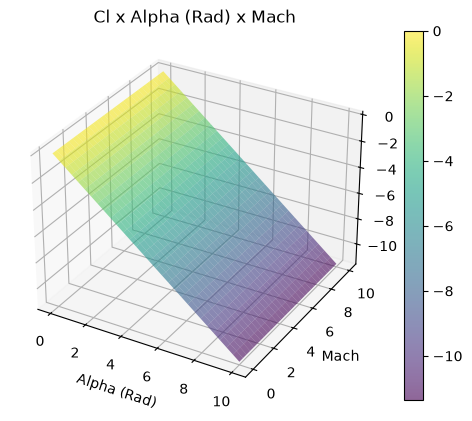

In [9]:
tail_data = component_data["boat_tail"]
tail = stormfly.add_tail(
    top_radius=tail_data["start_diameter"] / 2,
    bottom_radius=tail_data["end_diameter"] / 2,
    length=tail_data["length"],
    position=tail_data["position"],
)
if DISPLAY_EXTRA_INFO:
    tail.all_info()
del tail_data

In [10]:
stormfly.parachutes.clear()
parachutes: list[Parachute] = []
for parachute_data in component_data["recovery_system"]["stages"]:
    parachute: Parachute = stormfly.add_parachute(
        name=parachute_data["name"],
        cd_s=parachute_data["cd"],
        trigger=parachute_data["trigger"],
        sampling_rate=SENSOR_REFRESH_RATE,
        lag=parachute_data["delay"],
        noise=(0, 0, 0),
    )
    if DISPLAY_EXTRA_INFO:
        parachute.all_info()
    parachutes.append(parachute)
    del parachute


Parachute Details

Parachute Drogue with a cd_s of 0.9700 m2
Ejection signal trigger: At Apogee
Ejection system refresh rate: 100.000 Hz
Time between ejection signal is triggered and the parachute is fully opened: 0.1 s


Parachute Details

Parachute Main with a cd_s of 0.8000 m2
Ejection signal trigger: 457 m (AGL)
Ejection system refresh rate: 100.000 Hz
Time between ejection signal is triggered and the parachute is fully opened: 0.1 s



CG without motor: -0.7416381605965633 m
CG with no propellant: -0.8000564508659813 m
CG with propellant: -0.8627224241502547

Inertia Details

Rocket Mass: 4.627 kg (without motor)
Rocket Dry Mass: 5.399 kg (with unloaded motor)
Rocket Loaded Mass: 6.576 kg
Rocket Structural Mass Ratio: 0.821
Rocket Inertia (with unloaded motor) 11: 1.577 kg*m2
Rocket Inertia (with unloaded motor) 22: 1.577 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.012 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.04572 m
Rocket Frontal Area: 0.006567 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.058 m
Rocket Center of Dry Mass - Nozzle Exit: 0.629 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.350 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.063 m


Aerodynamics Lift Coefficient Derivat

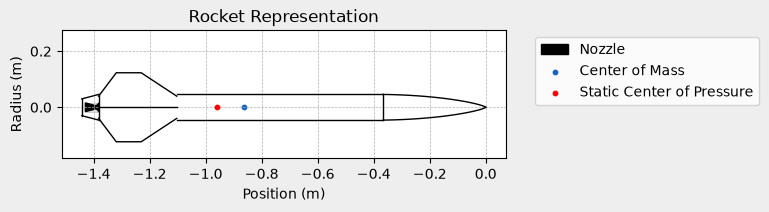


Mass Plots
----------------------------------------


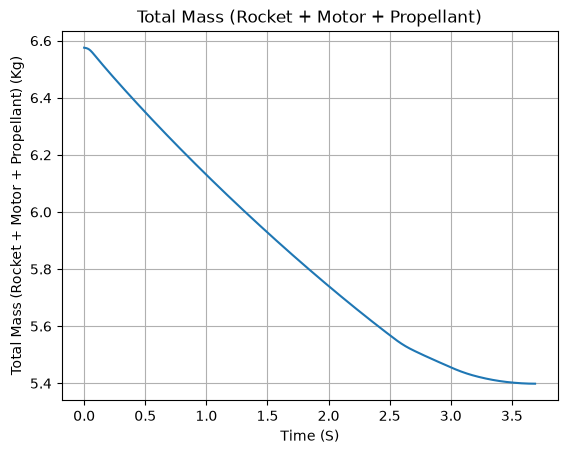

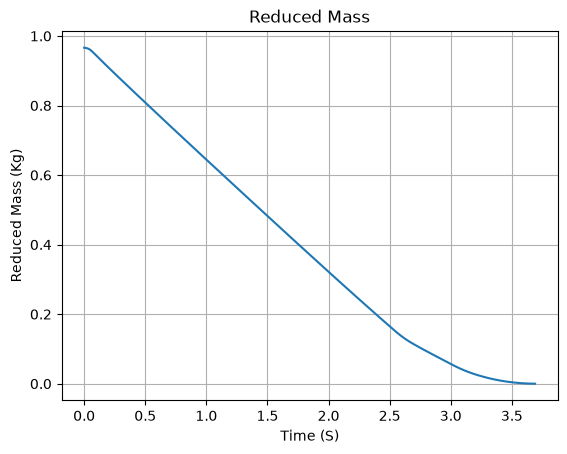


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


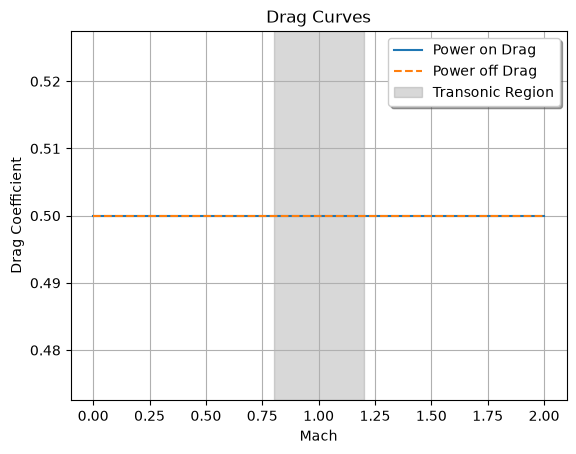


Stability Plots
--------------------


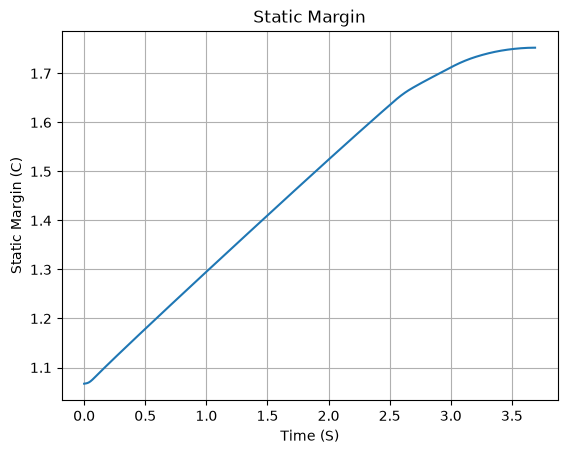

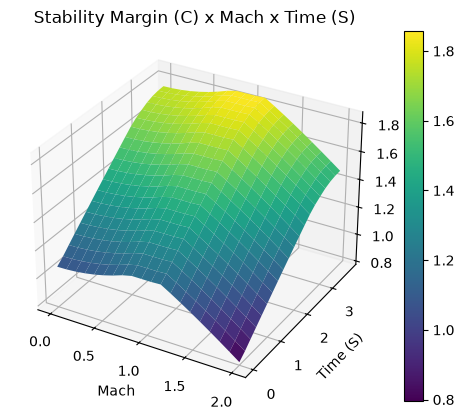


Thrust-to-Weight Plot
----------------------------------------


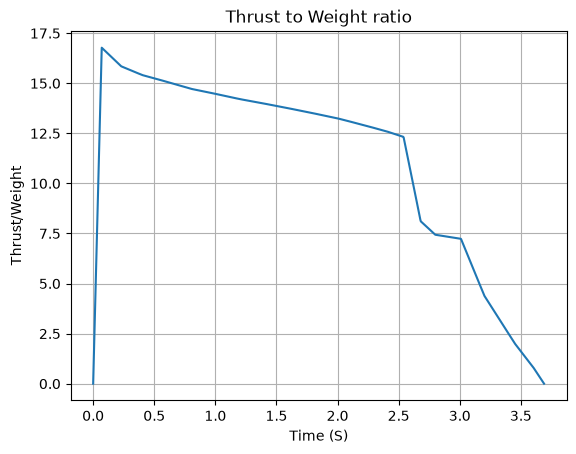

In [11]:
stormfly.warn_if_unstable()
print(f"CG without motor: {stormfly.center_of_mass_without_motor} m")
print(f"CG with no propellant: {stormfly.center_of_dry_mass_position} m")
print(f"CG with propellant: {stormfly.center_of_mass(0)}")
if DISPLAY_EXTRA_INFO:
    stormfly.all_info()
else:
    stormfly.draw()

In [12]:
flight = Flight(
    rocket=stormfly,
    environment=env,
    rail_length=launch_data["rail_length"],
    inclination=90-launch_data["rotation_angle"],
    heading=launch_data["heading"],
    terminate_on_apogee=STOP_AT_APOGEE,
    ode_solver="RK45",
)

c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\simulation\flight.py:676: UserWarning: The following arguments have no effect for a chosen solver: `min_step`.
  phase.solver = self._solver(



Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 910.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: -0.707 | e1: 0.012 | e2: 0.012 | e3: -0.707
Euler Angles - Spin φ : 0.00° | Nutation θ: -2.00° | Precession ψ: -270.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 1.067 c


Surface Wind Conditions

Frontal Surface Wind Speed: -4.50 m/s
Lateral Surface Wind Speed: 0.00 m/s


Launch Rail

Launch Rail Length: 4.3688 m
Launch Rail Inclination: 88.00°
Launch Rail Heading: 270.00°


Rail Departure State

Rail Departure Time: 0.370 s
Rail Departure Velocity: 49.070 m/s
Rail Departure Stability Margin: 1.151 c
Rail Departure Angle of Attack: 5.220°
Rail Departure Thrust-Weight Ratio: 15.492
Rail Departure Reynolds Number: 2.880e+05


Burn out State

Burn out time: 3.690 s
Altitude at burn out: 1674.527 m (ASL) | 764.527 m (AGL)
Rocket speed at burn out: 309.614 m/s
Freestre

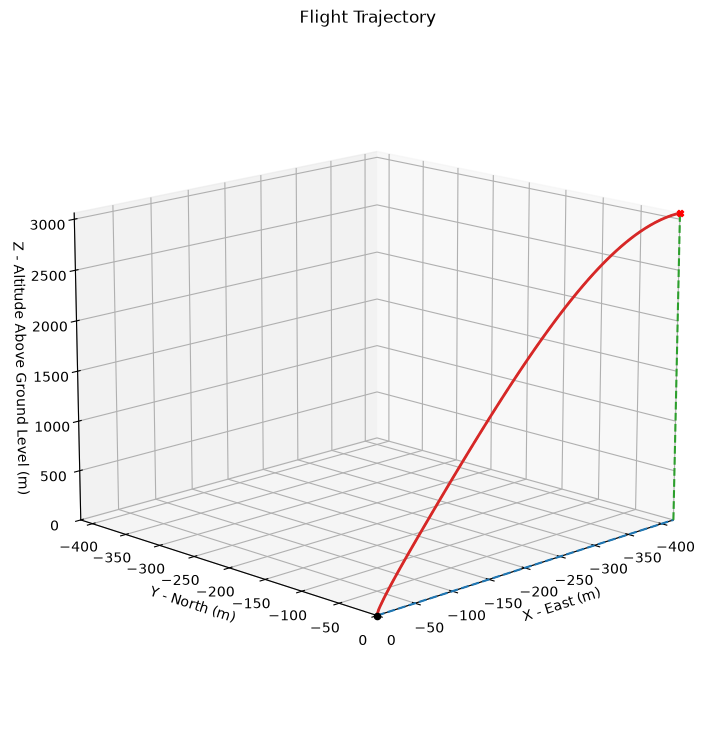



Trajectory Kinematic Plots



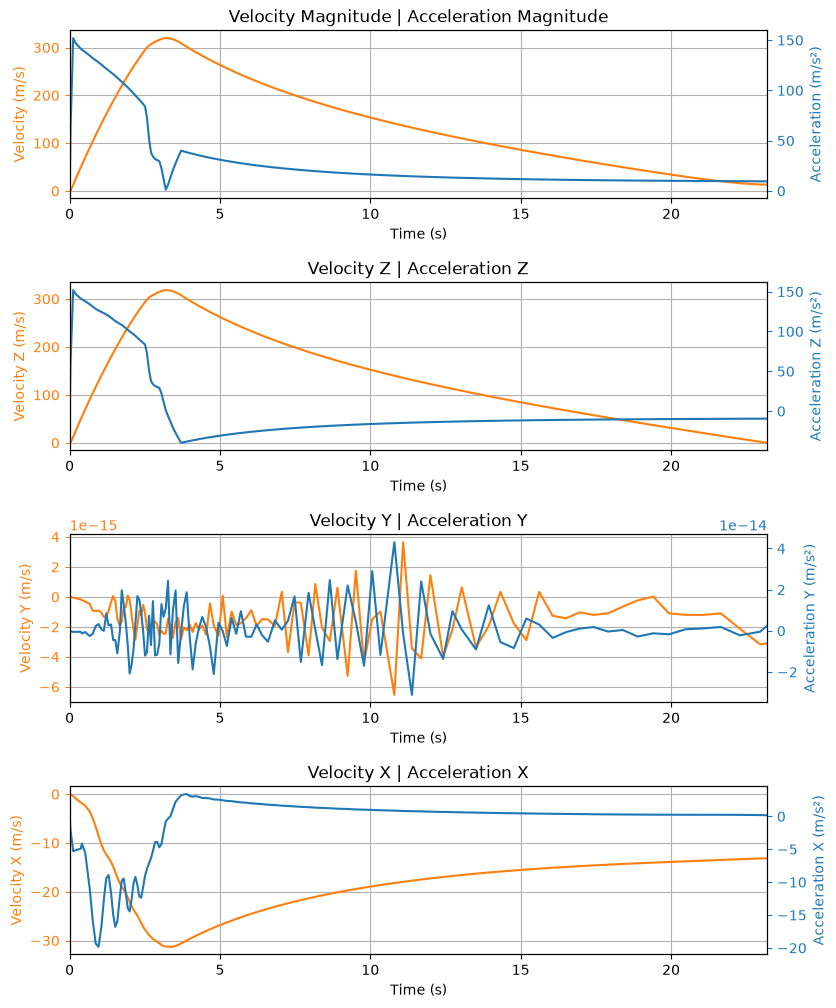



Angular Position Plots



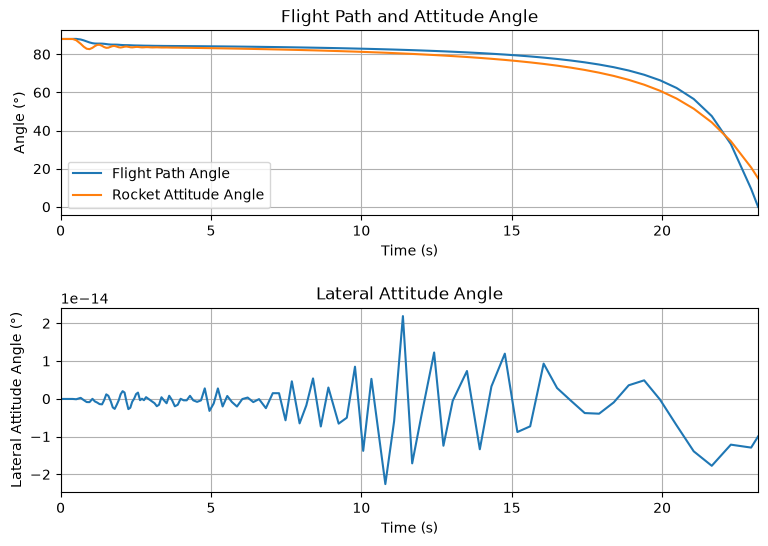



Path, Attitude and Lateral Attitude Angle Plots



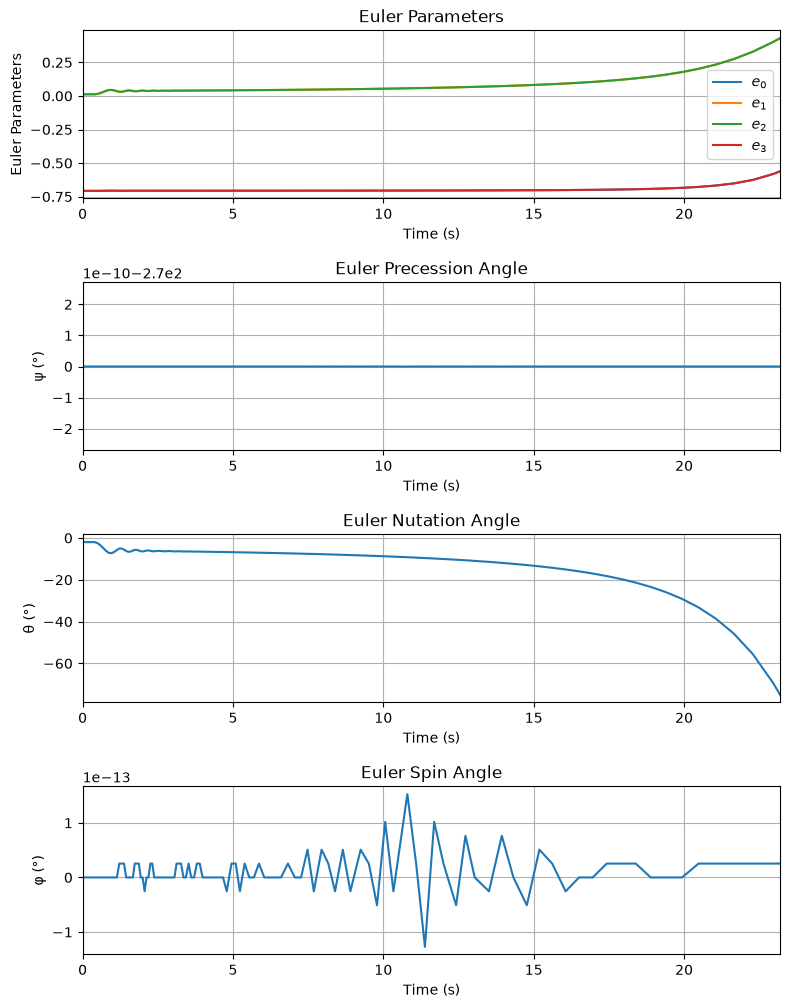



Trajectory Angular Velocity and Acceleration Plots



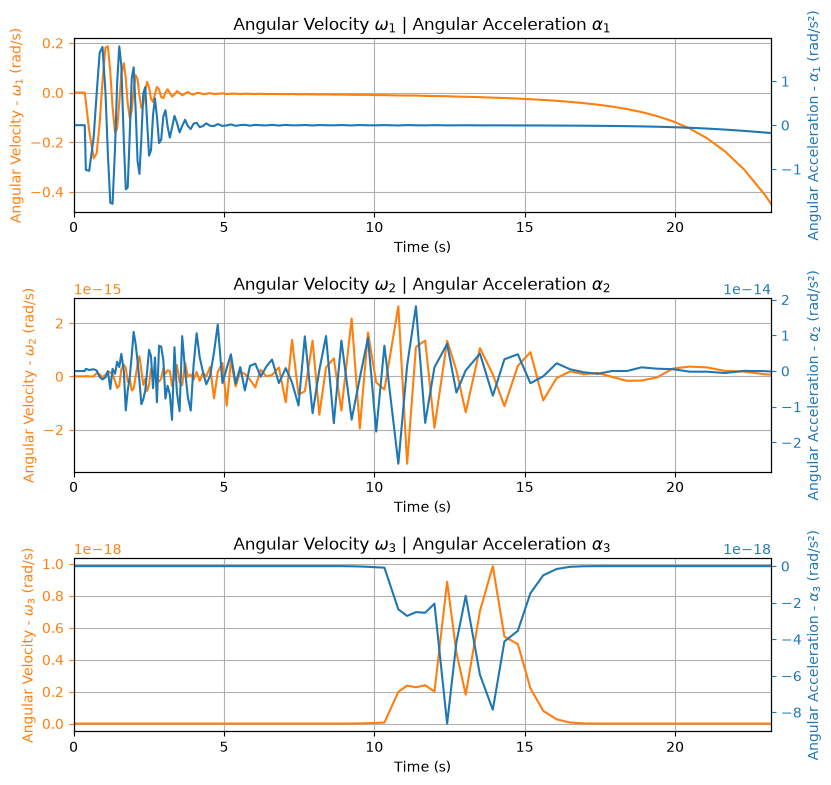



Aerodynamic Forces Plots



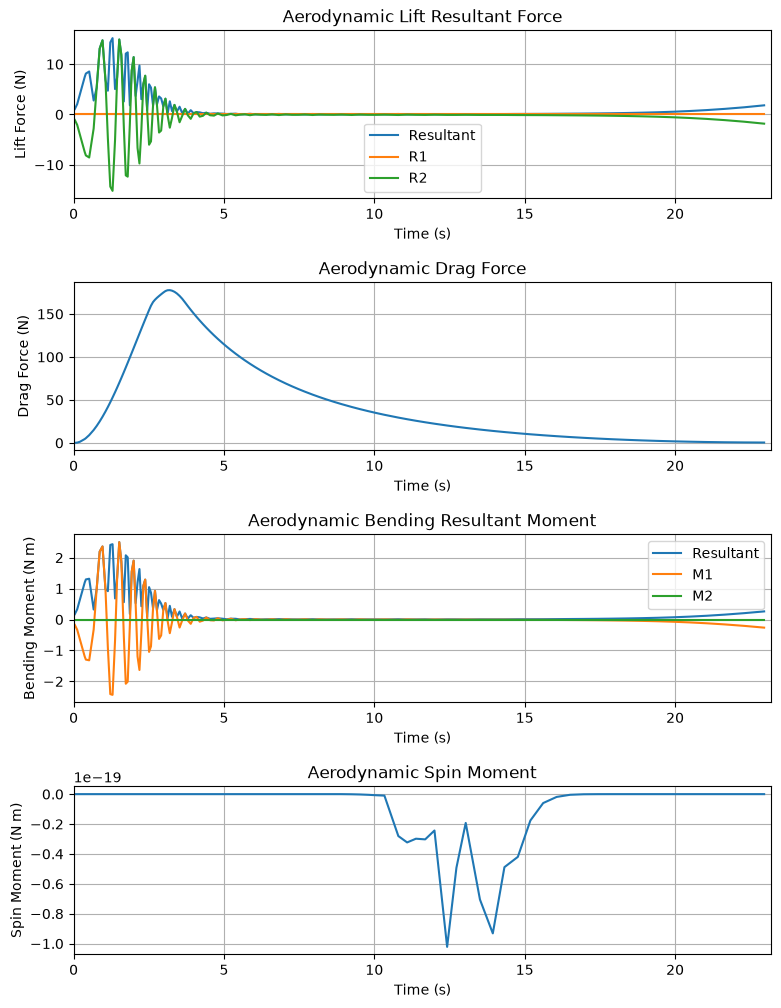

No rail buttons were defined. Skipping rail button bending moment plots.
No rail buttons were defined. Skipping rail button plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



Trajectory Energy Plots



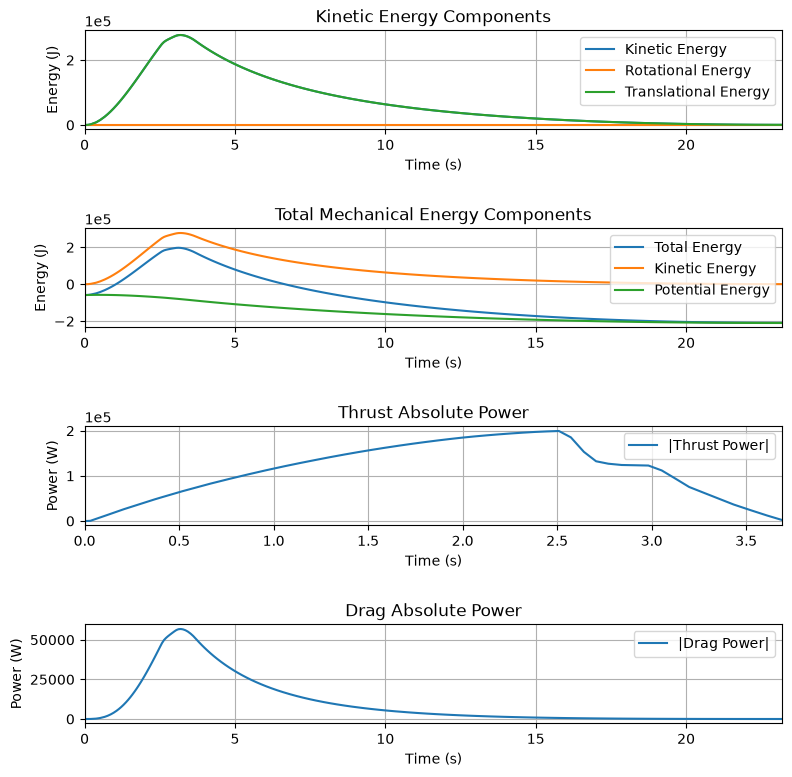



Trajectory Fluid Mechanics Plots



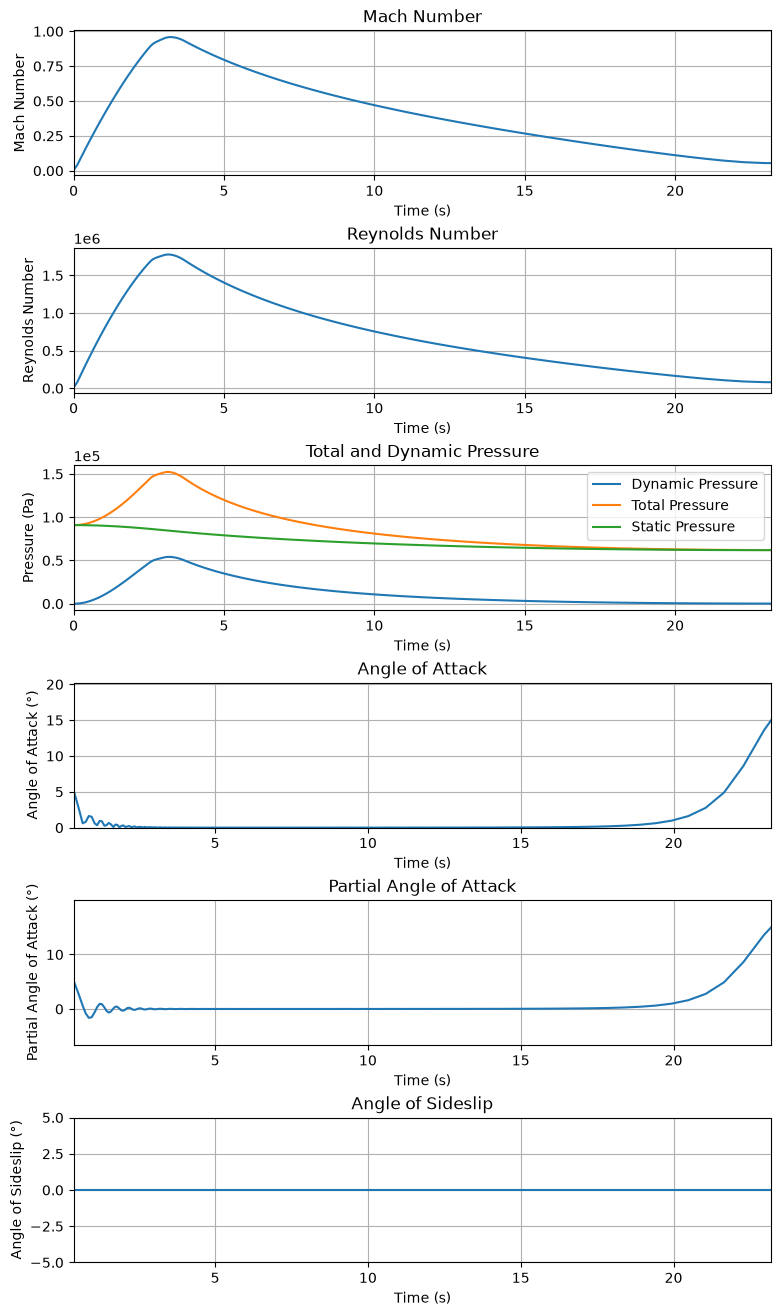



Trajectory Stability and Control Plots



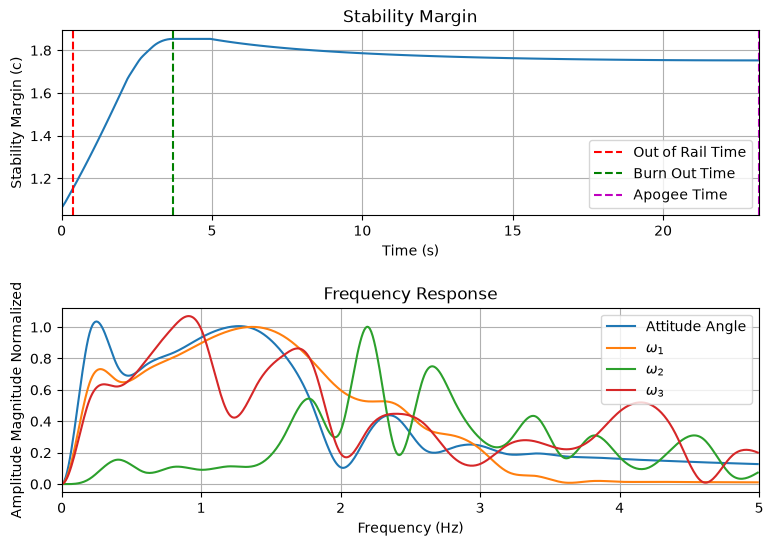



Rocket and Parachute Pressure Plots



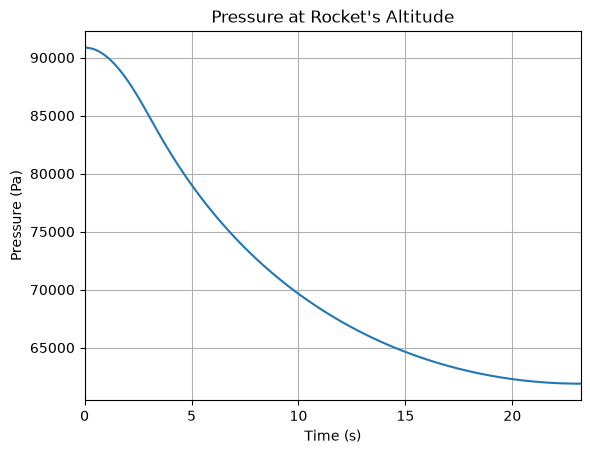

Rocket has no parachutes. No parachute plots available.


In [13]:
if DISPLAY_EXTRA_INFO:
    flight.all_info()
else:
    flight.info()
    flight.plots.trajectory_3d()

Added data source 'OpenRocket Sim' with variables: ['acceleration', 'aerodynamic_drag', 'altitude', 'angle_of_attack', 'az', 'latitude', 'longitude', 'vz', 'w1', 'w2', 'w3', 'x', 'y']

--------------------
COMPARISON REPORT: acceleration
--------------------
Source: OpenRocket Sim
  - MAE:            0.4526
  - RMSE:           1.2226
  - Max Deviation:  30.8223
  - Relative Error: 4.45%


c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\simulation\flight_comparator.py:132: UserWarning: Skipping 'time' in 'OpenRocket Sim'. Format not recognized. Expected RocketPy Function or (time, data) tuple.
  warnings.warn(
c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\plots\plot_helpers.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



--------------------
COMPARISON REPORT: aerodynamic_drag
--------------------
Source: OpenRocket Sim
  - MAE:            2.0757
  - RMSE:           3.0556
  - Max Deviation:  8.8395
  - Relative Error: 7.12%

--------------------
COMPARISON REPORT: altitude
--------------------
Source: OpenRocket Sim
  - MAE:            38.2032
  - RMSE:           49.1367
  - Max Deviation:  97.3675
  - Relative Error: 2.42%

--------------------
COMPARISON REPORT: angle_of_attack
--------------------
Source: OpenRocket Sim
  - MAE:            0.5102
  - RMSE:           1.2890
  - Max Deviation:  7.2854
  - Relative Error: 91.68%

--------------------
COMPARISON REPORT: az
--------------------
Source: OpenRocket Sim
  - MAE:            0.4867
  - RMSE:           1.2559
  - Max Deviation:  30.8041
  - Relative Error: 4.59%

--------------------
COMPARISON REPORT: latitude
--------------------
Source: OpenRocket Sim
  - MAE:            0.0000
  - RMSE:           0.0000
  - Max Deviation:  0.0000
  - Rel

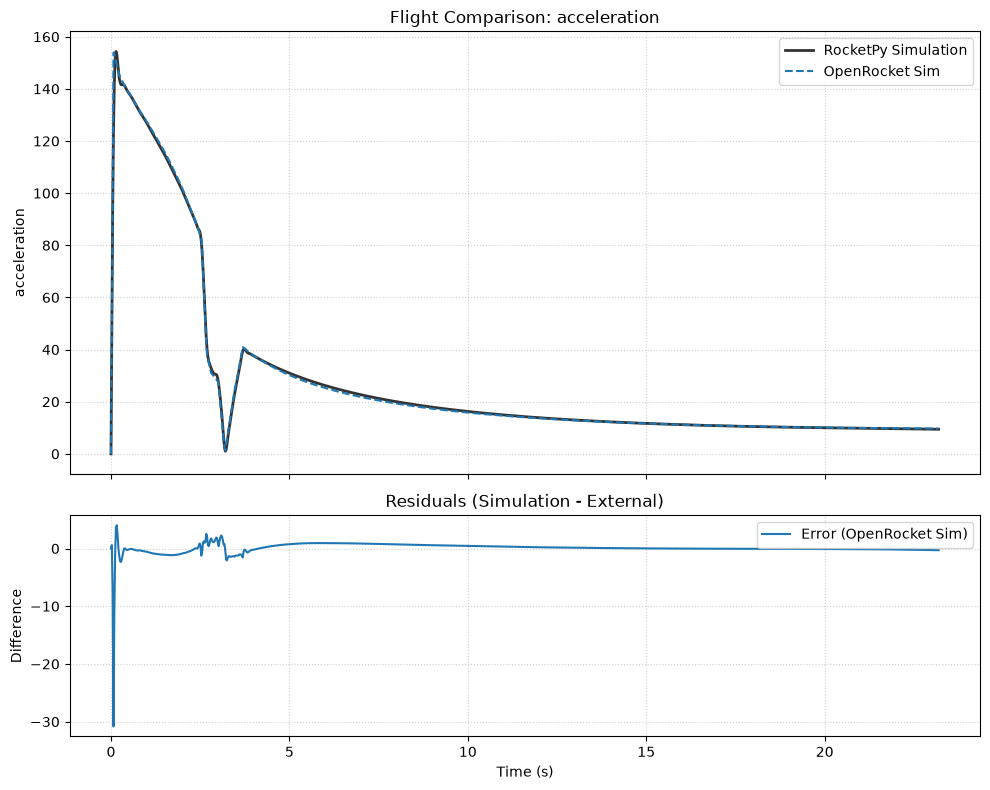

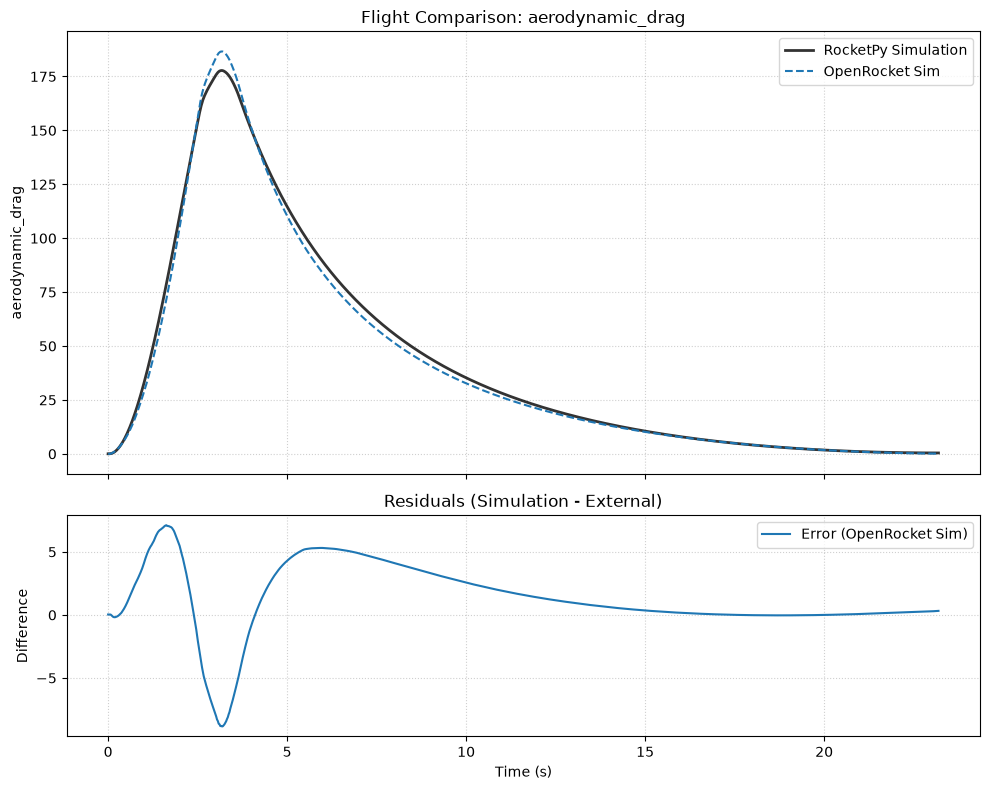

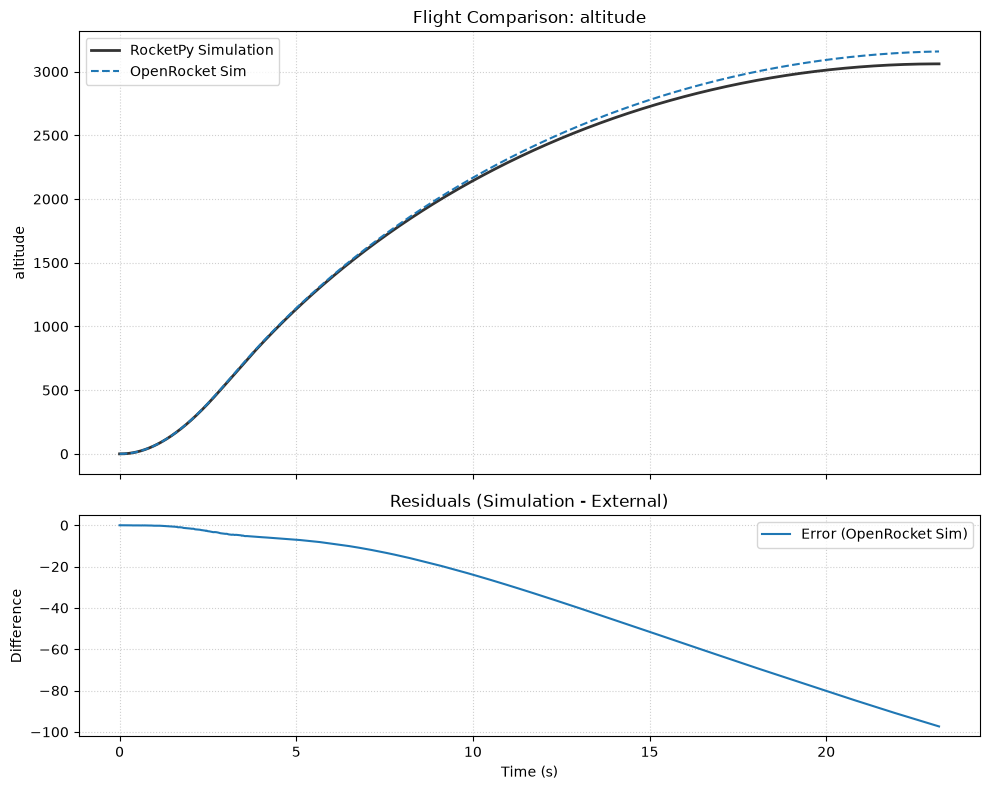

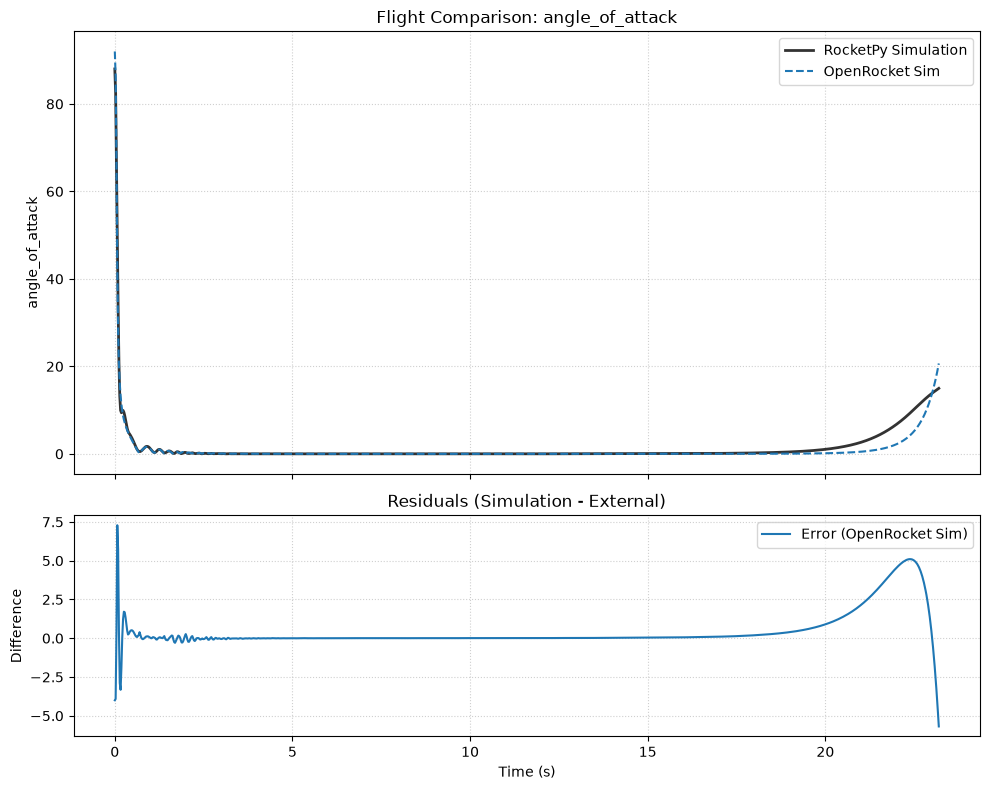

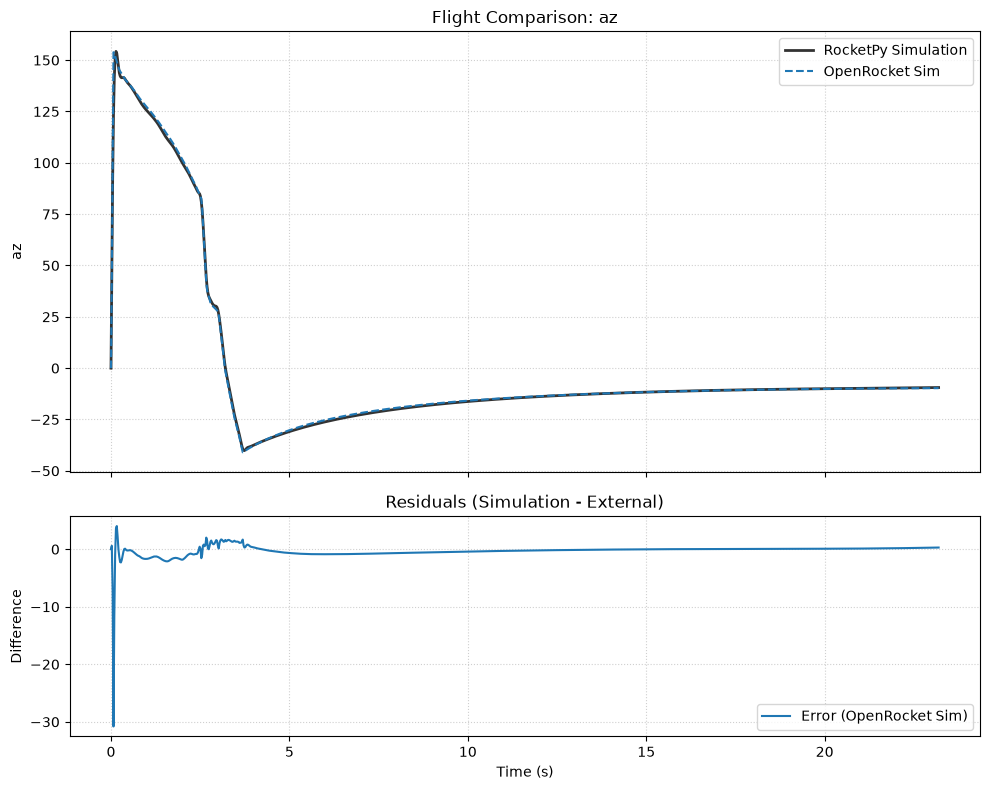

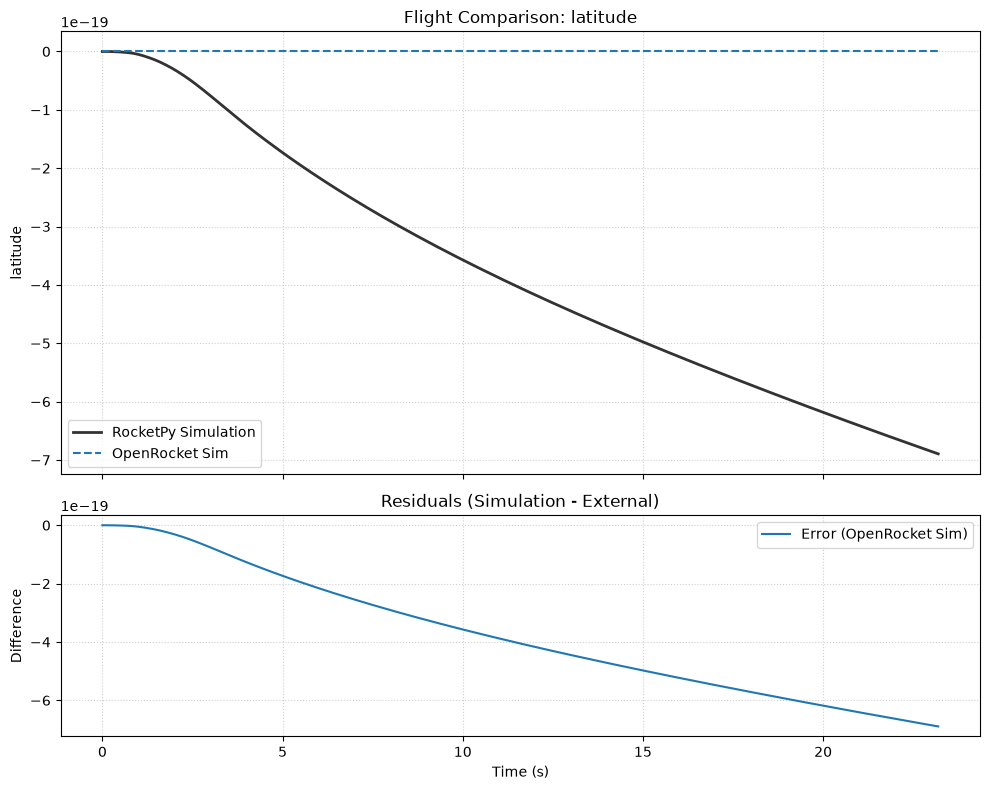

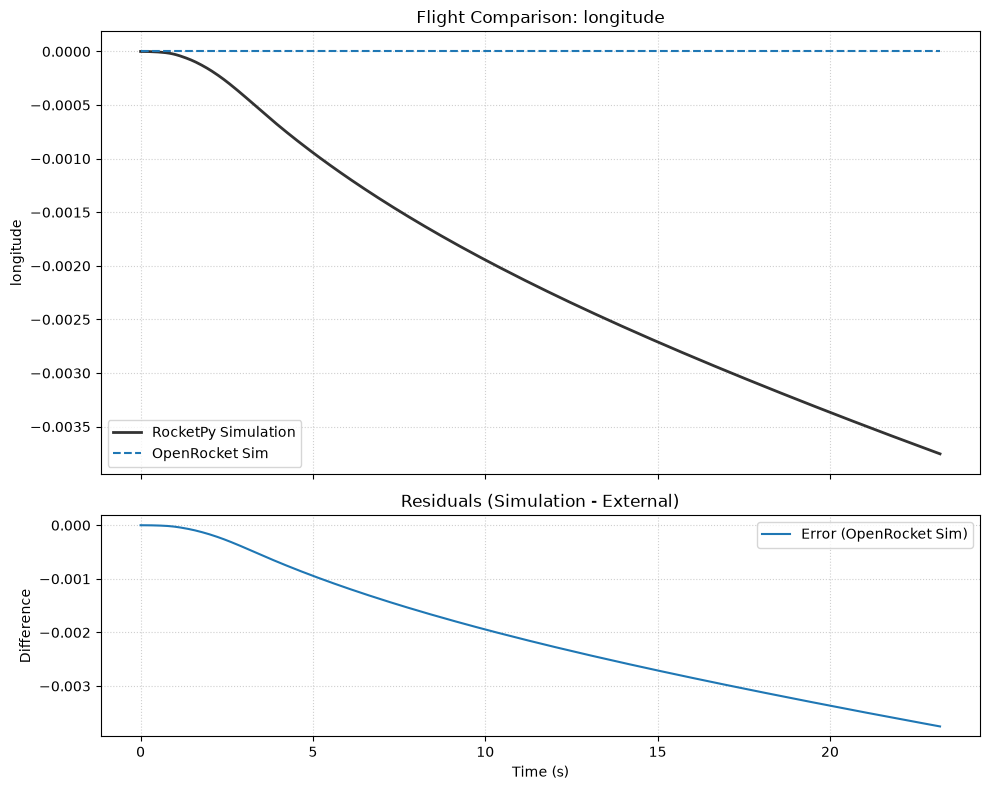

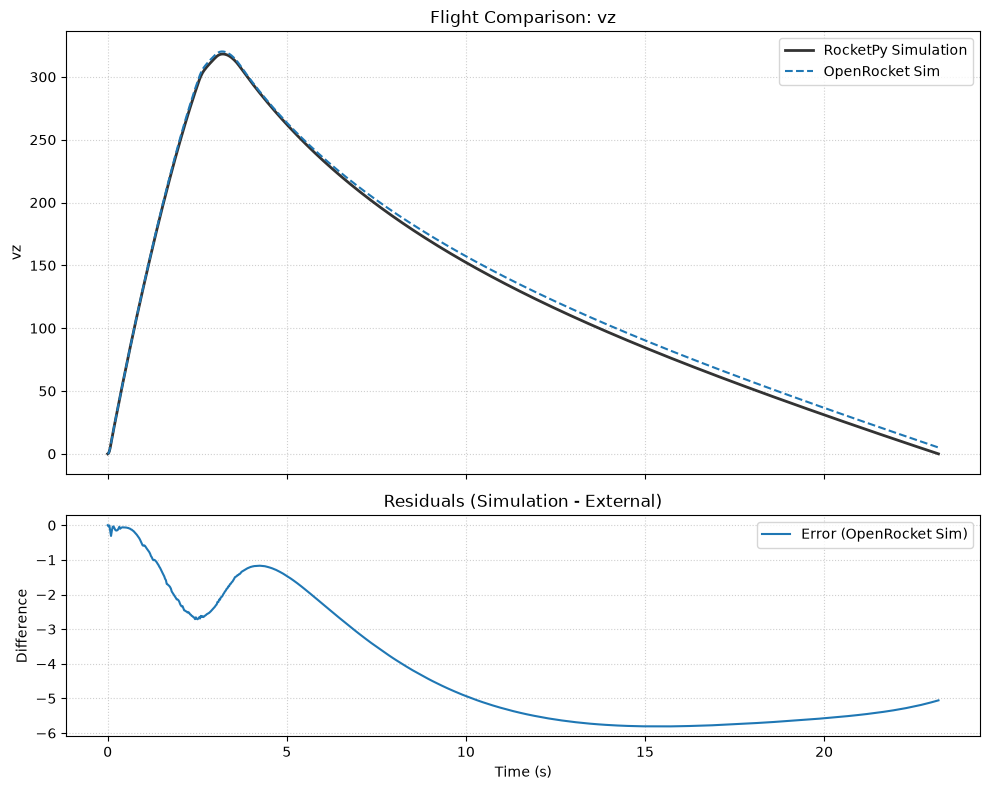

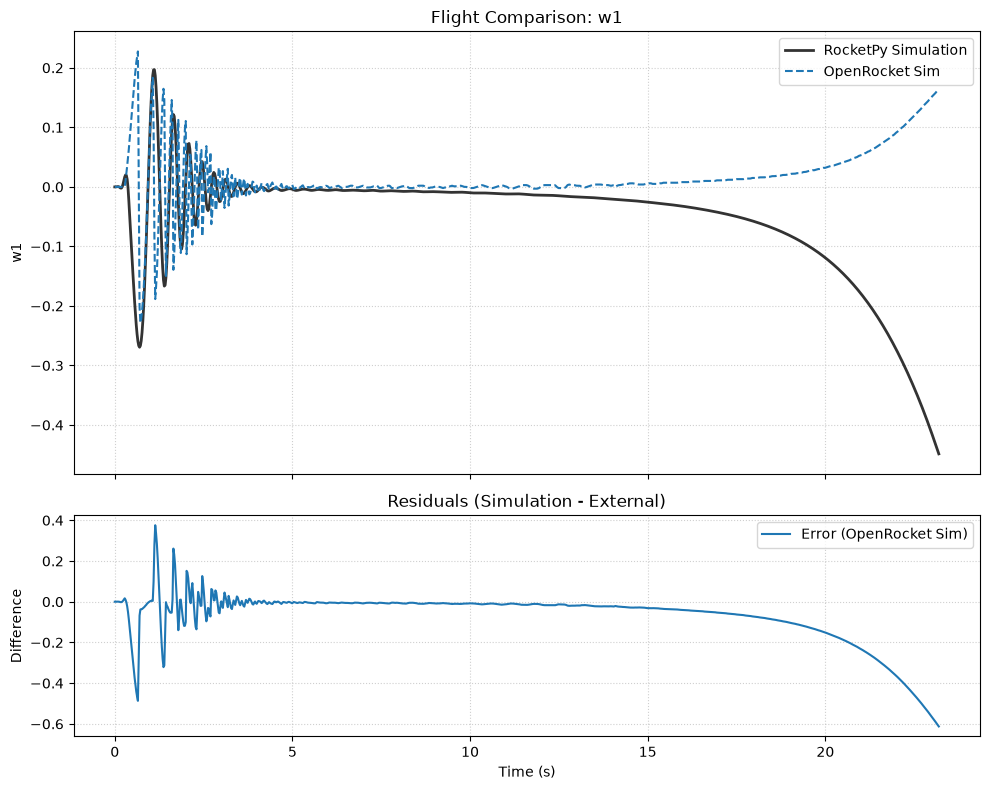

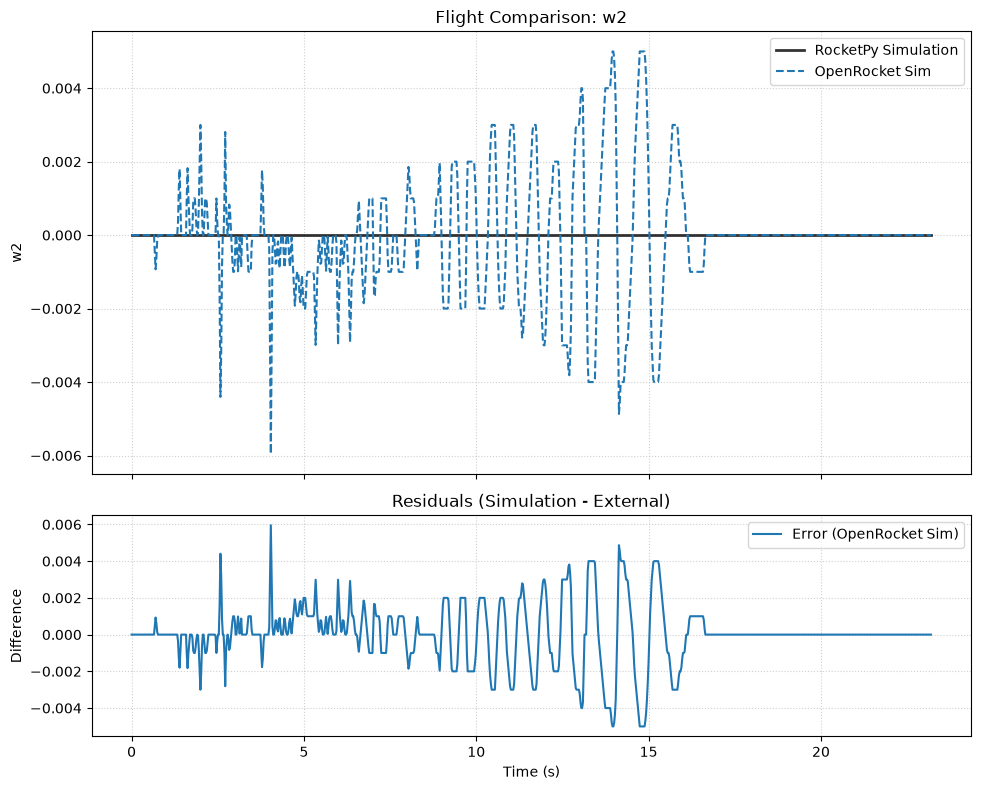

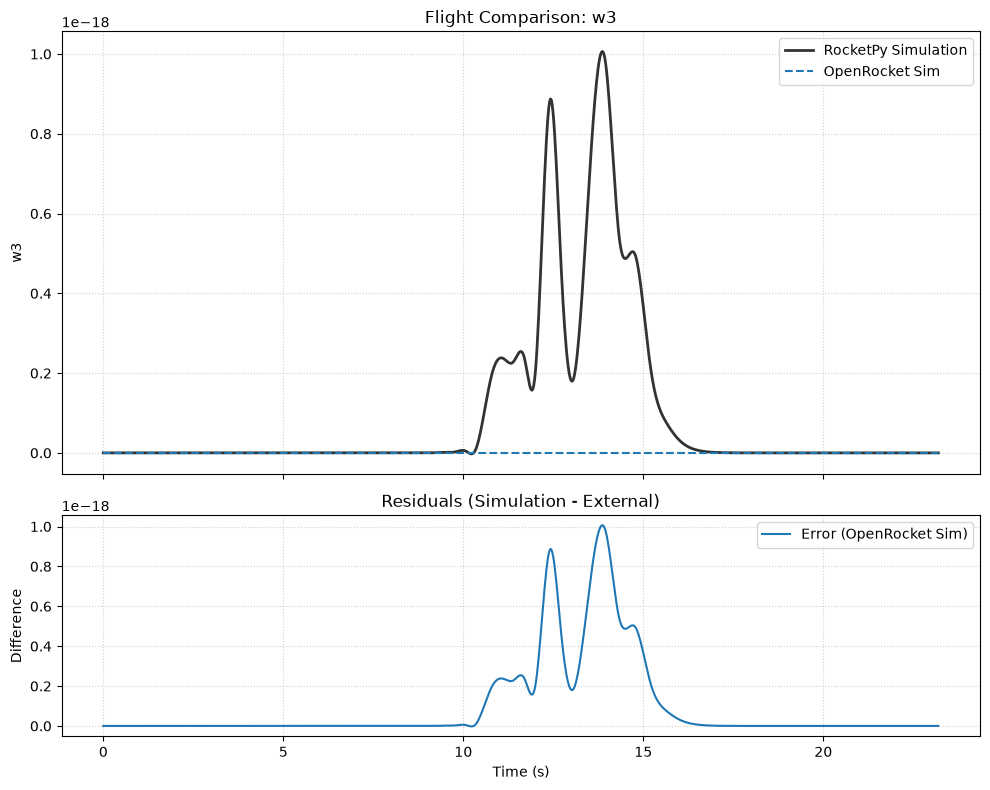

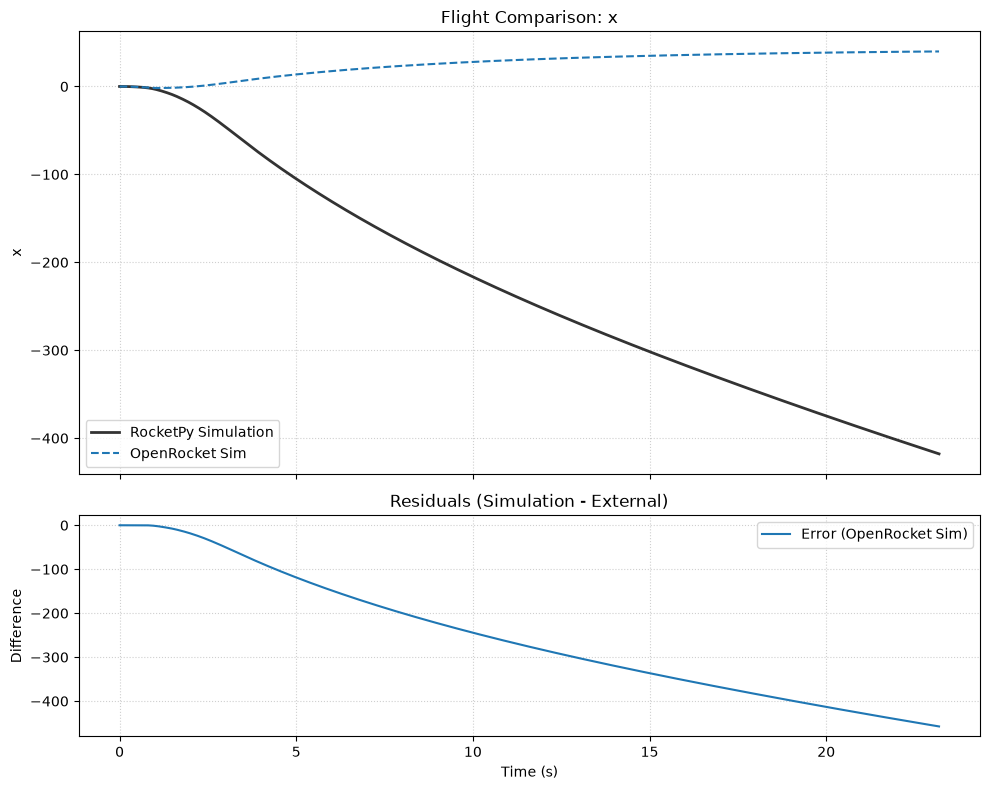

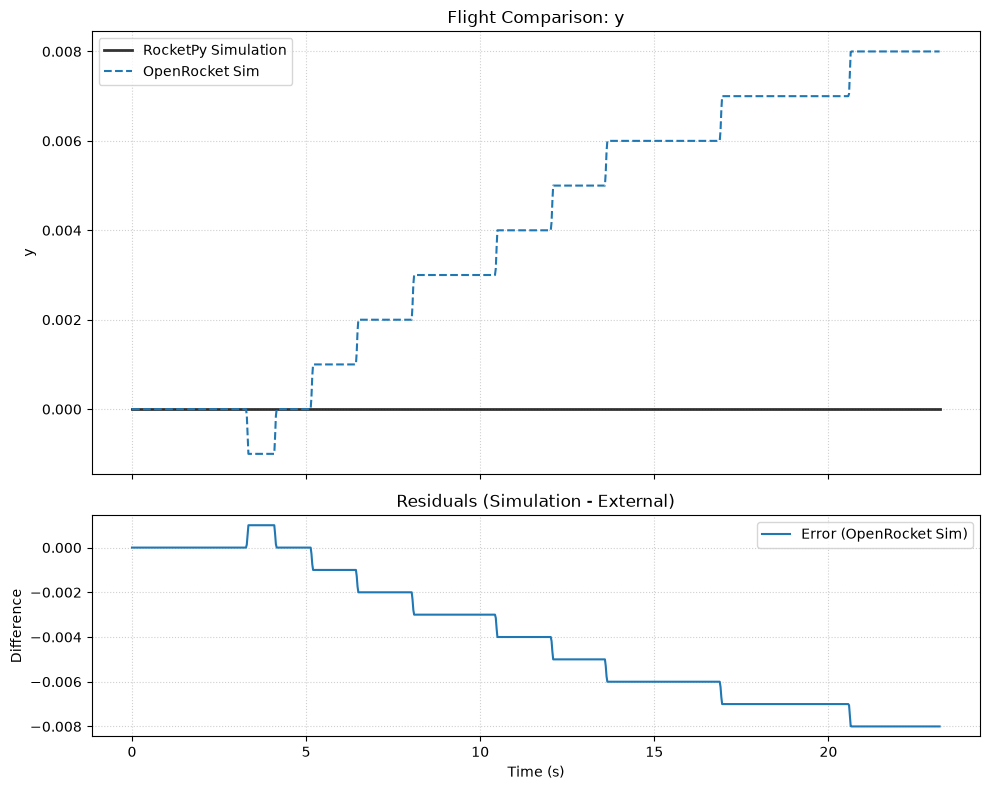

In [14]:
if COMPARISON_SIM_PATH:
    importer = FlightDataImporter(
        paths=COMPARISON_SIM_PATH,
        columns_map={
            "Time_(s)": "time",
            "Altitude_(m)": "altitude",
            "Altitude_above_sea_level (m)": "z",
            "Latitude_(°_N)": "latitude",
            "Longitude_(°_E)": "longitude",
            "Angle_of_attack_(°)": "angle_of_attack",
            "Vertical_velocity_(m/s)": "vz",
            "Vertical_acceleration_(m/s²)": "az",
            "Total_acceleration_(m/s²)": "acceleration",
            "Position_East_of_launch_(m)": "x",
            "Position_North_of_launch_(m)": "y",
            "Pitch_rate_(rad/s)": "w1",
            "Yaw_rate_(rad/s)": "w2",
            "Roll_rate_(rad/s)": "w3",
            "Stability_margin_calibers_()": "stability_margin",
            "Drag_force_(N)": "aerodynamic_drag",
        }
    )
    data_dict = {}
    for attribute in importer.flight_attributes:
        data_dict[attribute] = getattr(importer, attribute)
    comparator = FlightComparator(flight)
    comparator.add_data("OpenRocket Sim", data_dict)
    for attribute in importer.flight_attributes:
        if attribute != "time" and hasattr(flight, attribute) and isinstance(getattr(flight, attribute), Function):
            comparator.compare(attribute)
    del data_dict, importer

In [15]:
if EXPORT_FLIGHT_PATH:
    exporter = FlightDataExporter(flight)
    exporter.export_kml(file_name=EXPORT_FLIGHT_PATH, extrude=True, altitude_mode="relative_to_ground")
    del exporter

In [16]:
# This function needs pyvista installed, so running pip install rocketpy[animation]
# Big fix to make the animation work is to change flight_plots.py by adding a line before line 1204 (plotter.add_timer_event) and insert plotter.iren.initialize().
# flight_plots.py is at path [pathToEnvironment]/Lib/site-packages/rocketpy/plots/flight_plots.py
flight.plots.animate_trajectory(
    start=0,
    stop=flight.t_final,
    time_step=TIME_STEP,
    playback_speed=PLAYBACK_SPEED,
    background_color="#A8CBE0",
    color_by=COLOR_BY,
    show_kinematic_plots=True,      # altitude, speed and acceleration
    camera_mode=CAMERA_MODE,
    trajectory_line_width=8,        # flown-path width
    show_subrocket_point=True,      # ground projection
    force_external = True,          # force into new window
)

c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\plots\flight_plots.py:1225: UserWarning: Not within a jupyter notebook environment.
Ignoring ``jupyter_backend``.
  plotter.show(**show_kwargs)
c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\plots\flight_plots.py:1225: UserWarning: `auto_close` ignored: by clicking the exit button, you have destroyed the render window and we have to close it out.
  plotter.show(**show_kwargs)
